# Demonstrations

Demonstrative experiments to show:
1) The importance of evaluating prevalence for each homogeneous population individually
2) The value add of the method, in terms of increased coverage and confidence in estimates

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=9481)

# significance level for confidence intervals
ci_alpha = 0.05

In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

In [3]:
# Read in the full presence/absence data

# directory paths
project_root = Path.cwd().resolve().parent
data_dir = project_root / "data"

# presence/absence data
pa_df = pd.read_csv(
    data_dir / "pro_pangenome_presence_absence_data.csv",
    index_col=0,
).T

# metadata for the genomes in the clade-balanced dataset
genome_metadata_df = pd.read_csv(data_dir / "pro_pangenome_metadata.csv")
completeness_series = genome_metadata_df.set_index("genome")["completeness"] / 100

pa_df


gene_cluster_id,GC_00000001,GC_00000002,GC_00000003,GC_00000004,GC_00000005,GC_00000006,GC_00000007,GC_00000008,GC_00000009,GC_00000010,...,GC_00052849,GC_00052850,GC_00052851,GC_00052852,GC_00052853,GC_00052854,GC_00052855,GC_00052856,GC_00052857,GC_00052858
ProchlorococcusAC669I9,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669J22,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669O11,0,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K21,1,1,1,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAC669K20,1,1,0,1,1,0,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ProchlorococcusMIT1223,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG402N21,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409P19,1,1,1,1,1,1,1,1,1,1,...,0,0,0,0,0,0,0,0,0,0
ProchlorococcusAG409D09,1,1,1,1,1,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0


### Heterogeneity of clade subpopulations

Demonstration of the heterogeneity of the Pro population as a whole, and the homogeneity of individual clades

In [ ]:
# evaluate model on two independent samples of genomes

### Value add of method

- saturation curves to show how many new gene clusters are added with each new genome
- evaluation of change in CI widths with numbers of genomes sampled

In [4]:
# build saturation curve for each subset of genomes

# build lists of complete, incomplete, and all genomes
complete_genomes = genome_metadata_df.loc[genome_metadata_df['complete'], 'genome'].tolist()
incomplete_genomes = genome_metadata_df.loc[~genome_metadata_df['complete'], 'genome'].tolist()
all_genomes = genome_metadata_df['genome'].tolist()

# shuffle the lists of genomes to randomize the order in which they are added to the saturation curve
rng.shuffle(complete_genomes)
rng.shuffle(incomplete_genomes)
rng.shuffle(all_genomes)

# iterate through the lists of genomes and calculate the number of new gene clusters
# observed with the addition of each genome to the saturation curve
results = []
for i in range(1, len(all_genomes) + 1):
    for subset_name, genome_list in zip(
        ['complete', 'incomplete', 'all'],
        [complete_genomes, incomplete_genomes, all_genomes]
    ):
        if i > len(genome_list):
            continue
        subset_genomes = genome_list[:i]
        subset_pa_df = pa_df.loc[subset_genomes]
        n_genomes = len(subset_genomes)
        n_gene_clusters = (subset_pa_df.sum(axis=0) > 0).sum()
        results.append({
            'subset': subset_name,
            'n_genomes': n_genomes,
            'n_gene_clusters': n_gene_clusters
        })

saturation_df = pd.DataFrame(results)
saturation_df

,subset,n_genomes,n_gene_clusters
0,complete,1,2095
1,incomplete,1,946
2,all,1,345
3,complete,2,2306
4,incomplete,2,1187
...,...,...,...
2193,all,1095,52284
2194,all,1096,52291
2195,all,1097,52485
2196,all,1098,52490


In [ ]:
# evaluate how confidence interval width changes with increasing sample size for each subset of genomes

# set sample sizes to evaluate
sample_sizes = [
    1, 10, 20, 65, 100, 500, 1000, 1034, 1099, 
    # 1, 5, 10, 20, 30, 40, 50, 60, 65, 
    # 70, 80, 100, 200, 300, 400, 500, 
    # 600, 700, 800, 900, 1000, 1034, 1099
]

# iterate through sample sizes and subsets, fit Bernoulli prevalence model, and calculate confidence interval widths
results = []
for subset_name, genome_list in zip(
    ['complete', 'incomplete', 'all'],
    [complete_genomes, incomplete_genomes, all_genomes]
):
    for sample_size in sample_sizes:
        if sample_size > len(genome_list):
            continue
        print(f"Fitting model for subset '{subset_name}' with sample size {sample_size}...")
        subset_genomes = genome_list[:sample_size]
        subset_pa_df = pa_df.loc[subset_genomes]
        # fit prevalence model using true completeness levels as input
        model = BernoulliPrevalenceModel(
            data=subset_pa_df, 
            lambdas=completeness_series.loc[subset_genomes], 
            )
        fit = model.fit(
            estimator="mle",
            interval_method="likelihood_ratio",
            alpha=ci_alpha,
            clip=True
        )
        pi_hat = fit.prevalence
        ci_lower, ci_upper = fit.confidence_interval()
        ci_widths = ci_upper - ci_lower
        results.append({
            'subset': subset_name,
            'sample_size': sample_size,
            'mean_ci_width': ci_widths.mean(),
            'std_ci_width': ci_widths.std(),
            'core_size': (pi_hat == 1.0).sum(),  # number of gene clusters with estimated prevalence of 1.0
            'expanded_core_size': ((pi_hat >= 0.9)).sum(),  # number of gene clusters with estimated prevalence of 0.9 or higher
            'alt_expanded_core_size': ((ci_upper >= 1.0).sum())  # number of gene clusters with upper confidence interval bound that includes 1.0
        })

ci_width_df = pd.DataFrame(results)
ci_width_df

Fitting model for subset 'complete' with sample size 1...
Fitting model for subset 'complete' with sample size 10...
Fitting model for subset 'complete' with sample size 20...
Fitting model for subset 'complete' with sample size 65...
Fitting model for subset 'incomplete' with sample size 1...
Fitting model for subset 'incomplete' with sample size 10...
Fitting model for subset 'incomplete' with sample size 20...
Fitting model for subset 'incomplete' with sample size 65...
Fitting model for subset 'incomplete' with sample size 100...
Fitting model for subset 'incomplete' with sample size 500...


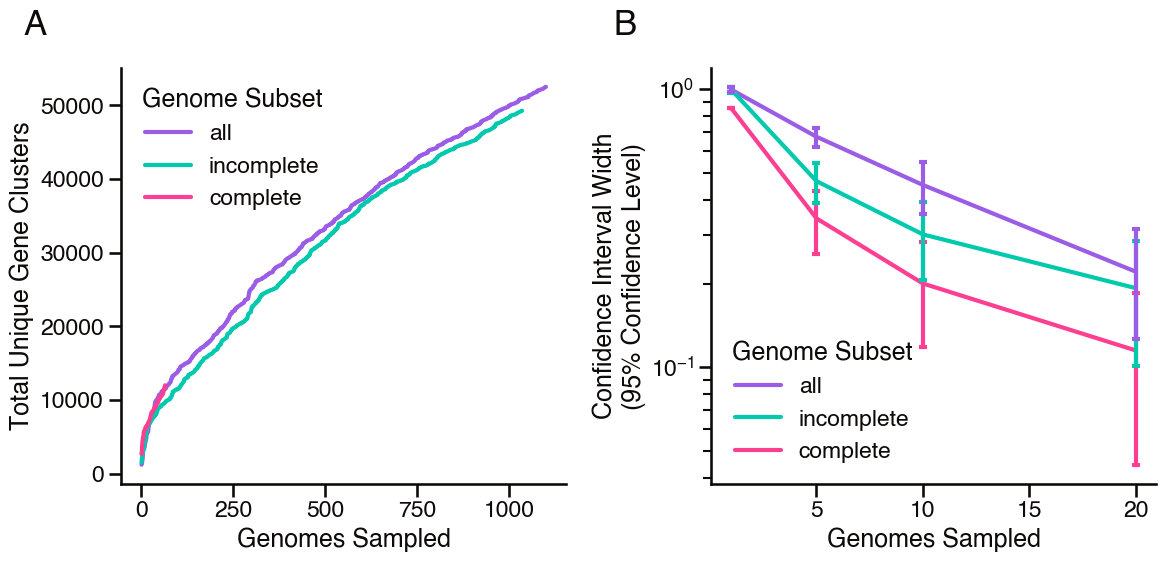

In [ ]:
# build two panel figure showing (A) saturation curves for each subset of genomes and 
# (B) how confidence interval width changes with increasing sample size for each subset of genomes

# set up figure and axes
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# annotation specs
annotation_kwargs = dict(
    xy=(-0.22, 1.08),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: saturation curves
sns.lineplot(
    data=saturation_df,
    x="n_genomes",
    y="n_gene_clusters",
    hue="subset",
    hue_order=['all', 'incomplete', 'complete'],
    palette=[palette[i] for i in [0, 2, 3]],
    linewidth=3,
    ax=axes[0]
)
axes[0].set_xlabel("Genomes Sampled")
axes[0].set_ylabel("Total Unique Gene Clusters")
axes[0].legend(title="Genome Subset")
# add annotation for panel A
axes[0].annotate("A", **annotation_kwargs)

# plot B: confidence interval widths
sns.lineplot(
    data=ci_width_df,
    x="sample_size",
    y="mean_ci_width",
    hue="subset",
    hue_order=['all', 'incomplete', 'complete'],
    palette=[palette[i] for i in [0, 2, 3]],
    linewidth=3,
    ax=axes[1]
)
# add error bars representing standard deviation of confidence interval widths across gene clusters
for subset_name, color in zip(
    ['complete', 'incomplete', 'all'],
    [palette[i] for i in [3, 2, 0]]
):
    subset_df = ci_width_df.loc[ci_width_df['subset'] == subset_name]
    axes[1].errorbar(
        x=subset_df['sample_size'],
        y=subset_df['mean_ci_width'],
        yerr=subset_df['std_ci_width'],
        fmt='none',
        ecolor=color,
        capsize=3, 
        capthick=3,
        elinewidth=3,
    )
axes[1].set_xlabel("Genomes Sampled")
axes[1].set_ylabel(f"Confidence Interval Width\n({(1 - ci_alpha) * 100:.0f}% Confidence Level)")
axes[1].set_yscale('log')
axes[1].legend(title="Genome Subset")
# add annotation for panel B
axes[1].annotate("B", **annotation_kwargs)

# save and show the figure
plt.tight_layout()
# plt.savefig("ci_width_saturation_curves.png", dpi=300)
plt.show()

In [16]:
completeness_series

genome
ProchlorococcusAC669I9     0.6591
ProchlorococcusAC669J22    0.6528
ProchlorococcusAC669O11    0.6319
ProchlorococcusAC669K21    0.5731
ProchlorococcusAC669K20    0.5587
                            ...  
ProchlorococcusMIT1223     1.0000
ProchlorococcusAG402N21    0.7619
ProchlorococcusAG409P19    0.6711
ProchlorococcusAG409D09    0.6491
ProchlorococcusAG435K18    0.5947
Name: completeness, Length: 1099, dtype: float64